In [2]:
#load n clean
import pandas as pd
import numpy as np
df = pd.read_csv(
    r"C:\Users\Sanju\Downloads\goibibo_flights_data.csv",
    usecols=range(11))
df.columns = df.columns.str.strip()
df['price'] = pd.to_numeric(df['price'].str.replace(',', '').str.strip(), errors='coerce')
df['stops'] = df['stops'].str.strip().str.split('\n').str[0]
df['flight date'] = pd.to_datetime(df['flight date'], dayfirst=True)
df['route'] = df['from'].str.strip() + ' → ' + df['to'].str.strip()
df.dropna(subset=['price'], inplace=True)
print(f"Records after cleaning: {len(df):,}")

Records after cleaning: 300,261


In [3]:
#2 — Airline Market Share
airline_share = (
    df.groupby('airline')
    .agg(flights=('price','count'), median_price=('price','median'))
    .assign(share_pct=lambda x: x['flights']/len(df)*100)
    .sort_values('flights', ascending=False)
)
print(airline_share)

           flights  median_price  share_pct
airline                                    
Vistara     127859       15698.0  42.582620
Air India    80894       11635.0  26.941228
Indigo       43120        4498.0  14.360839
GO FIRST     23177        5389.0   7.718951
AirAsia      16098        3309.0   5.361336
SpiceJet      9011        5711.0   3.001056
StarAir         61        4380.0   0.020316
Trujet          41        3228.0   0.013655


In [4]:
#3 — Stop Distribution KPI
stop_dist = df['stops'].value_counts()
one_stop_pct = stop_dist.get('1-stop', 0) / len(df) * 100
print(f"1-Stop: {one_stop_pct:.1f}% of all flights")

1-Stop: 83.6% of all flights


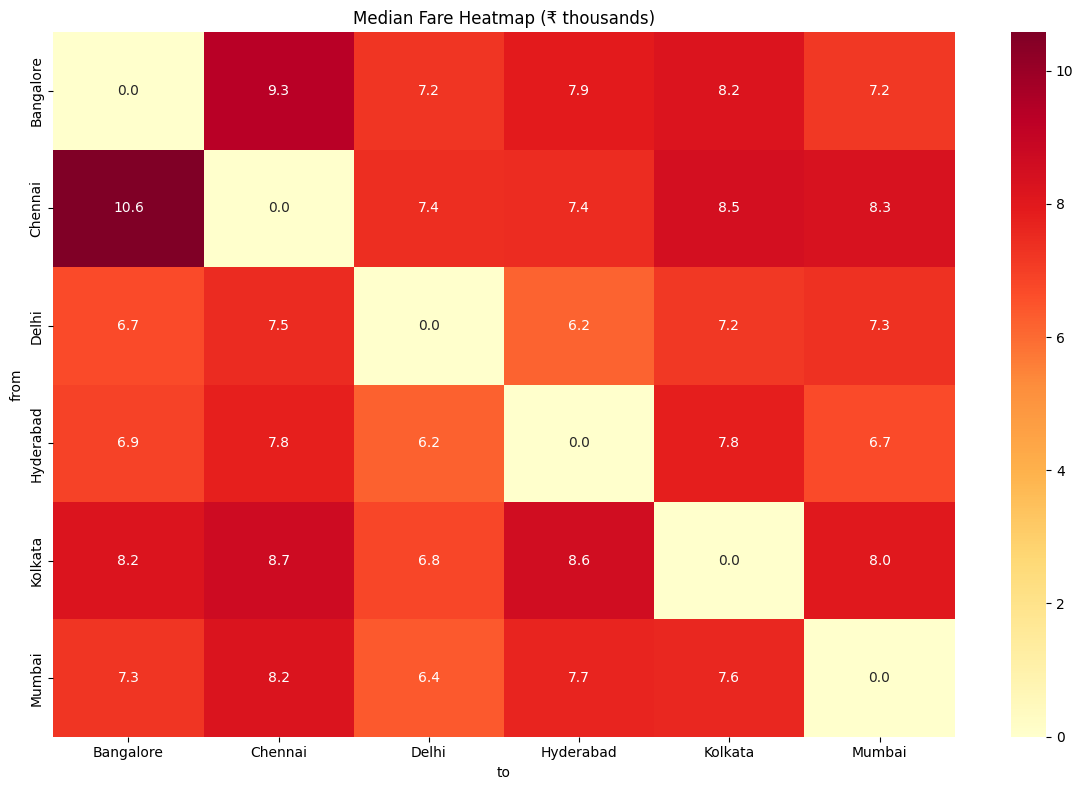

In [5]:
#4 — Route Heatmap (Median Price)
import seaborn as sns
import matplotlib.pyplot as plt

pivot = df.groupby(['from','to'])['price'].median().unstack(fill_value=0)
plt.figure(figsize=(12,8))
sns.heatmap(pivot/1000, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Median Fare Heatmap (₹ thousands)')
plt.tight_layout()
plt.savefig('route_heatmap.png', dpi=150)


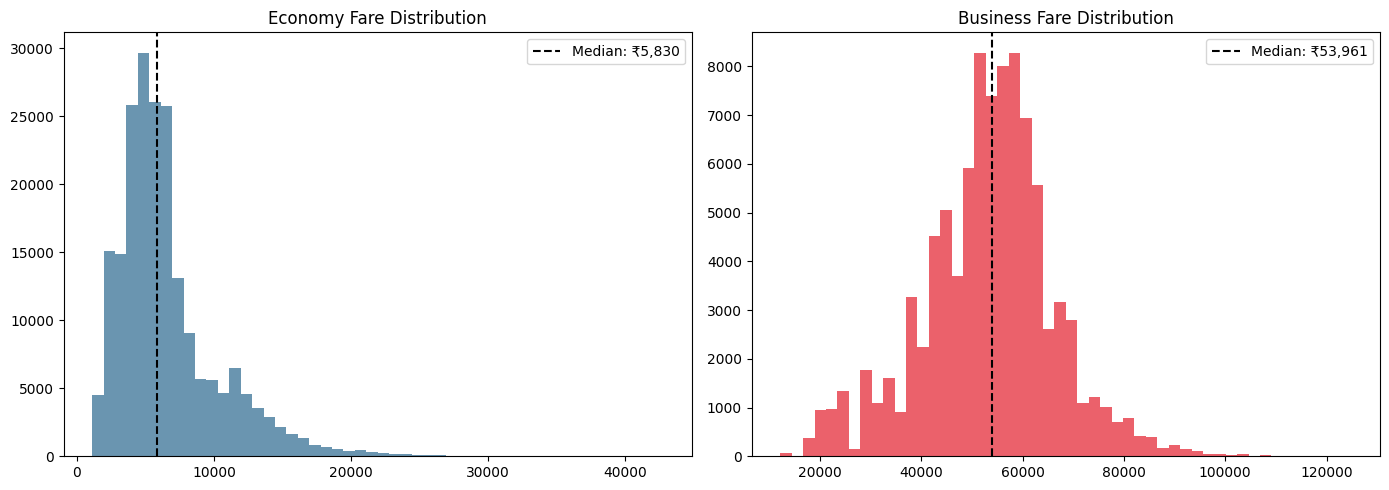

In [12]:
#5 — Fare Distribution (Economy vs Business)
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cls in zip(axes, ['economy', 'business']):
    data = df[df['class'] == cls]['price']
    ax.hist(data, bins=50, color='#457b9d' if cls=='economy' else '#e63946', alpha=0.8)
    ax.axvline(data.median(), color='black', linestyle='--', label=f'Median: ₹{data.median():,.0f}')
    ax.set_title(f'{cls.title()} Fare Distribution')
    ax.legend()
plt.tight_layout()
plt.savefig('fare_distribution.png', dpi=150)


In [6]:
#6 — Price Anomaly / Premium Detection
route_median = df.groupby('route')['price'].median()
df['route_median'] = df['route'].map(route_median)
df['price_ratio'] = df['price'] / df['route_median']
premium = df[df['price_ratio'] > 2].sort_values('price_ratio', ascending=False)
print(f"Premium-priced tickets (>2x median): {len(premium):,}")
print(premium[['route','airline','class','price','route_median','price_ratio']].head(10))

Premium-priced tickets (>2x median): 101,646
                     route  airline     class   price  route_median  \
219291   Delhi → Hyderabad  Vistara  business  116225        6170.0   
261485     Kolkata → Delhi  Vistara  business  124917        6790.0   
225463      Mumbai → Delhi  Vistara  business  113109        6363.0   
277453  Hyderabad → Mumbai  Vistara  business  116939        6699.0   
219340   Delhi → Hyderabad  Vistara  business  106562        6170.0   
216204     Delhi → Kolkata  Vistara  business  119067        7155.0   
215967     Delhi → Kolkata  Vistara  business  118310        7155.0   
262304     Kolkata → Delhi  Vistara  business  110855        6790.0   
215966     Delhi → Kolkata  Vistara  business  116151        7155.0   
261607     Kolkata → Delhi  Vistara  business  109985        6790.0   

        price_ratio  
219291    18.837115  
261485    18.397202  
225463    17.776049  
277453    17.456187  
219340    17.270989  
216204    16.641090  
215967    16.535290

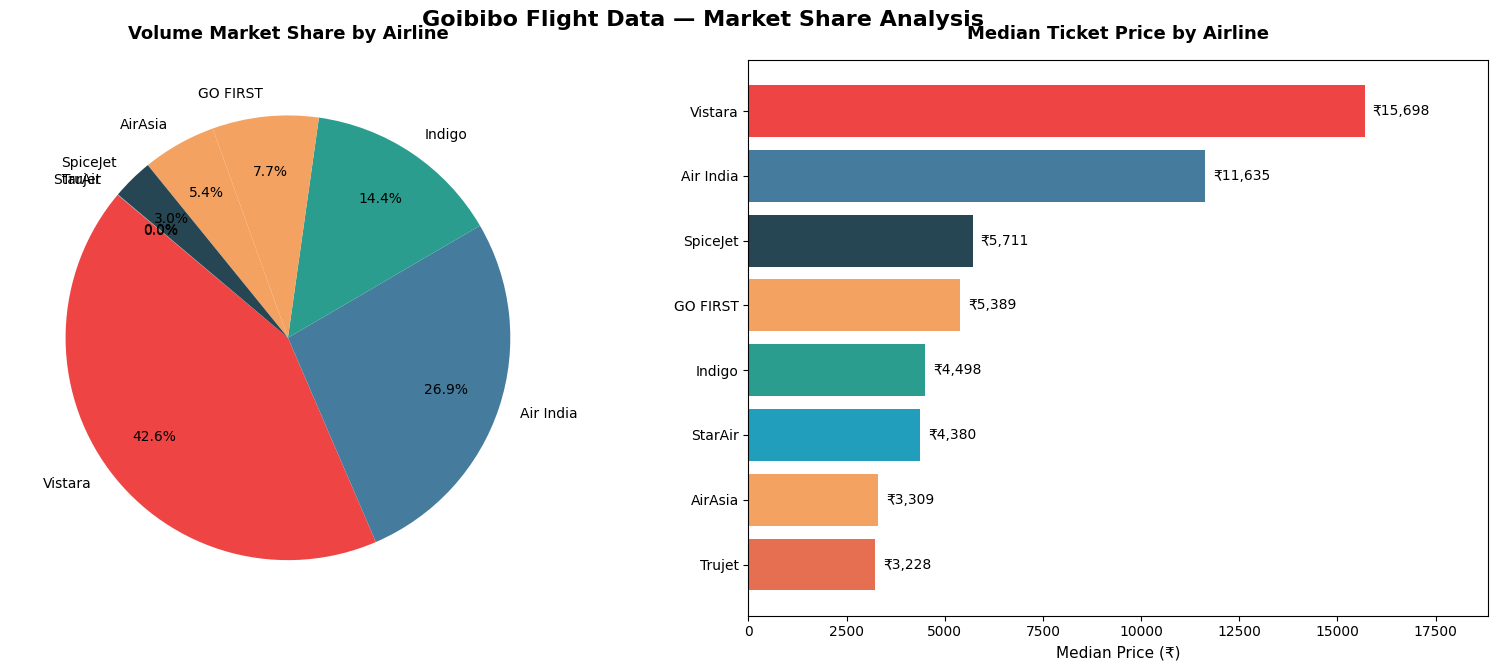

In [11]:

# Clean column names just in case
df.columns = df.columns.str.strip()

# 1. Data Processing (using your actual lowercase column names)
market_share = df['airline'].value_counts(normalize=True) * 100
median_price = (
    df.groupby('airline')['price'].median().sort_values(ascending=True)
)

# 2. Color Palette matching the chart styling
airline_colors = {
    'Vistara': '#ef4444',
    'Air India': '#457b9d',
    'Indigo': '#2a9d8f',
    'GO FIRST': '#f4a261',
    'AirAsia': '#f4a261',
    'SpiceJet': '#264653',
    'StarAir': '#219ebc',
    'Trujet': '#e76f51',
}

bar_colors = [
    airline_colors.get(airline, '#3b82f6')
    for airline in median_price.index
]
pie_colors = [
    airline_colors.get(airline, '#3b82f6')
    for airline in market_share.index
]

# 3. Create Subplots Layout
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

fig.suptitle(
    'Goibibo Flight Data — Market Share Analysis',
    fontsize=16,
    fontweight='bold',
    y=0.95,
)

# Left Panel: Volume Market Share (Pie Chart)
ax1.pie(
    market_share,
    labels=market_share.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=pie_colors,
    pctdistance=0.75,
)
ax1.set_title(
    'Volume Market Share by Airline', fontsize=13, fontweight='bold', pad=15
)

# Right Panel: Median Ticket Price (Horizontal Bar Chart)
bars = ax2.barh(median_price.index, median_price.values, color=bar_colors)
ax2.set_title(
    'Median Ticket Price by Airline', fontsize=13, fontweight='bold', pad=15
)
ax2.set_xlabel('Median Price (₹)', fontsize=11)

# Add exact price labels next to each bar
for bar in bars:
  width = bar.get_width()
  ax2.text(
      width + 200,
      bar.get_y() + bar.get_height() / 2,
      f'₹{int(width):,}',
      va='center',
      ha='left',
      fontsize=10,
      color='black',
  )

ax2.set_xlim(0, max(median_price.values) * 1.2)

plt.tight_layout()
plt.show()

C:\Users\Sanju\AppData\Local\Temp\ipykernel_20092\2571952822.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(


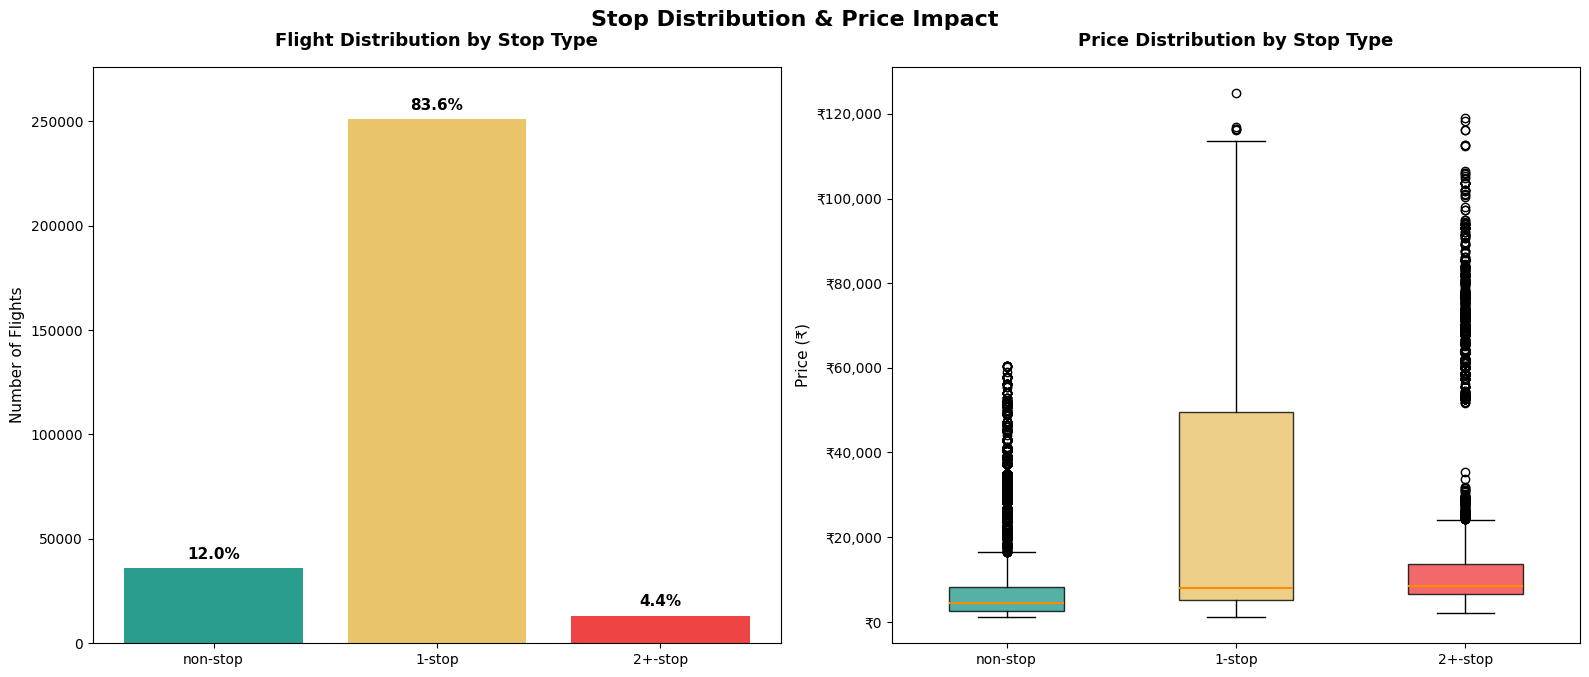

In [17]:
df.columns = df.columns.str.strip()

# 1. Data Preparation
# Group / sort stop categories logically if needed (e.g., non-stop, 1-stop, 2+-stop)
stop_counts = df['stops'].value_counts()

# Ensure standard ordering if present
preferred_order = ['non-stop', '1-stop', '2+-stop']
# Filter ordering to match whatever exists in your dataframe
stop_order = [s for s in preferred_order if s in stop_counts.index]
# If your values are named differently (like integers or other strings), fallback to index sorting:
if not stop_order:
  stop_order = stop_counts.index.tolist()

# Calculate counts and percentages for the left chart
counts_sorted = df['stops'].value_counts().reindex(stop_order)
total_flights = len(df)
percentages_sorted = (counts_sorted / total_flights) * 100

# Prepare data for the boxplot (right chart)
box_data = [df[df['stops'] == stop]['price'].dropna() for stop in stop_order]

# 2. Color Palette matching the chart styling
stop_colors = ['#2a9d8f', '#e9c46a', '#ef4444']  # Teal, Gold/Orange, Red

# 3. Create Subplots Layout
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

fig.suptitle(
    'Stop Distribution & Price Impact',
    fontsize=16,
    fontweight='bold',
    y=0.96,
)

# --- Left Panel: Flight Distribution by Stop Type (Bar Chart) ---
bars = ax1.bar(
    stop_order, counts_sorted.values, color=stop_colors[: len(stop_order)]
)
ax1.set_title(
    'Flight Distribution by Stop Type', fontsize=13, fontweight='bold', pad=15
)
ax1.set_ylabel('Number of Flights', fontsize=11)

# Add percentage labels on top of each bar
for bar, pct in zip(bars, percentages_sorted.values):
  height = bar.get_height()
  ax1.text(
      bar.get_x() + bar.get_width() / 2,
      height + 3000,
      f'{pct:.1f}%',
      ha='center',
      va='bottom',
      fontsize=11,
      fontweight='bold',
  )

ax1.set_ylim(0, max(counts_sorted.values) * 1.1)

# --- Right Panel: Price Distribution by Stop Type (Box Plot) ---
bp = ax2.boxplot(
    box_data,
    labels=stop_order,
    patch_artist=True,
    widths=0.5,
    medianprops=dict(color='darkorange', linewidth=1.5),
)

# Apply custom colors to the boxes
for patch, color in zip(bp['boxes'], stop_colors[: len(stop_order)]):
  patch.set_facecolor(color)
  patch.set_alpha(0.8)

ax2.set_title(
    'Price Distribution by Stop Type', fontsize=13, fontweight='bold', pad=15
)
ax2.set_ylabel('Price (₹)', fontsize=11)

# Format y-axis ticks with Indian Rupee symbol and comma separators
from matplotlib.ticker import FuncFormatter

ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f'₹{int(x):,}' if x >= 0 else '')
)

# Final Layout Adjustments
plt.tight_layout()
plt.show()

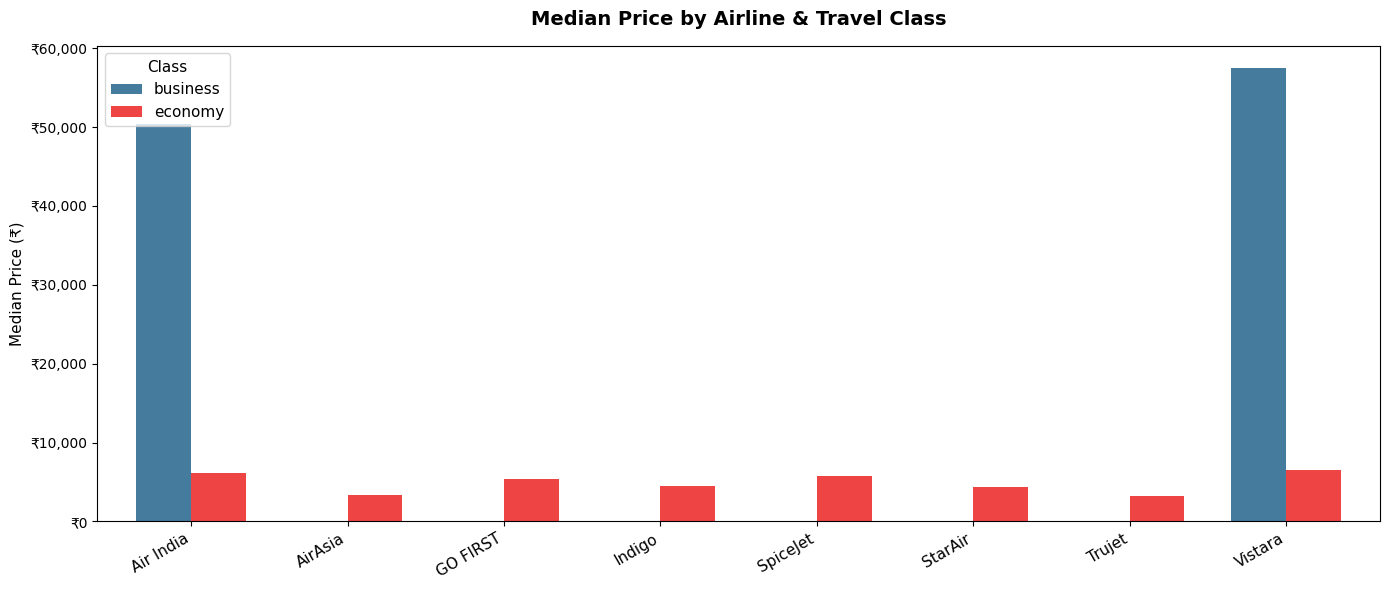

In [18]:
# Group data by airline and class, then calculate the median price
median_price_class = (
    df.groupby(['airline', 'class'])['price'].median().unstack(fill_value=0)
)

# Set up figure
fig, ax = plt.subplots(figsize=(14, 6))

# Plot grouped bar chart using pandas/matplotlib
colors = ['#457b9d', '#ef4444']  # Steel Blue for business, Red for economy
median_price_class.plot(
    kind='bar', ax=ax, color=colors, width=0.7, edgecolor='none'
)

# Chart styling and title
ax.set_title(
    'Median Price by Airline & Travel Class',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
ax.set_ylabel('Median Price (₹)', fontsize=11)
ax.set_xlabel('', fontsize=11)  # Clear x-axis label as names are self-explanatory

# Rotate x-axis labels for clean readability
plt.xticks(rotation=30, ha='right', fontsize=11)

# Format y-axis with Indian Rupee formatting
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f'₹{int(x):,}' if x >= 0 else '')
)

# Legend configuration
ax.legend(title='Class', fontsize=11, title_fontsize=11, loc='upper left')

# Layout adjustment
plt.tight_layout()
plt.show()

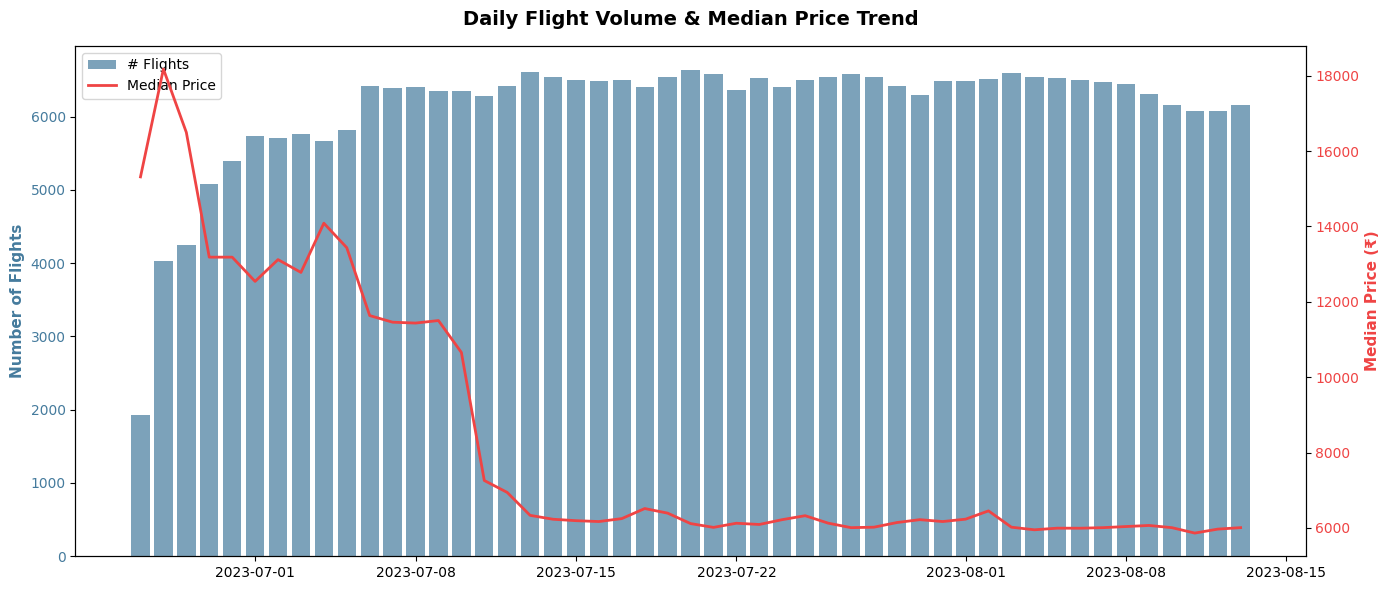

In [19]:
# 1. Data Preparation: Aggregate daily counts and median prices
daily_df = df.groupby('flight date').agg(
    flight_count=('price', 'count'), median_price=('price', 'median')
).reset_index()

# Ensure dates are in datetime format for proper time-series plotting
daily_df['flight date'] = pd.to_datetime(daily_df['flight date'])
daily_df = daily_df.sort_values('flight date')

# 2. Set up the figure with a dual y-axis (`twinx`)
fig, ax1 = plt.subplots(figsize=(14, 6))

# Primary Axis: Bar Chart for Flight Volume
color_bars = '#457b9d'
ax1.bar(
    daily_df['flight date'],
    daily_df['flight_count'],
    color=color_bars,
    alpha=0.7,
    label='# Flights',
)
ax1.set_ylabel('Number of Flights', color=color_bars, fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_bars)

# Secondary Axis: Line Chart for Median Price
ax2 = ax1.twinx()
color_line = '#ef4444'
ax2.plot(
    daily_df['flight date'],
    daily_df['median_price'],
    color=color_line,
    linewidth=2,
    label='Median Price',
)
ax2.set_ylabel(
    'Median Price (₹)', color=color_line, fontsize=11, fontweight='bold'
)
ax2.tick_params(axis='y', labelcolor=color_line)

# Title & Layout Styling
plt.title(
    'Daily Flight Volume & Median Price Trend',
    fontsize=14,
    fontweight='bold',
    pad=15,
)

# Combine legends from both axes into one panel
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.tight_layout()
plt.show()

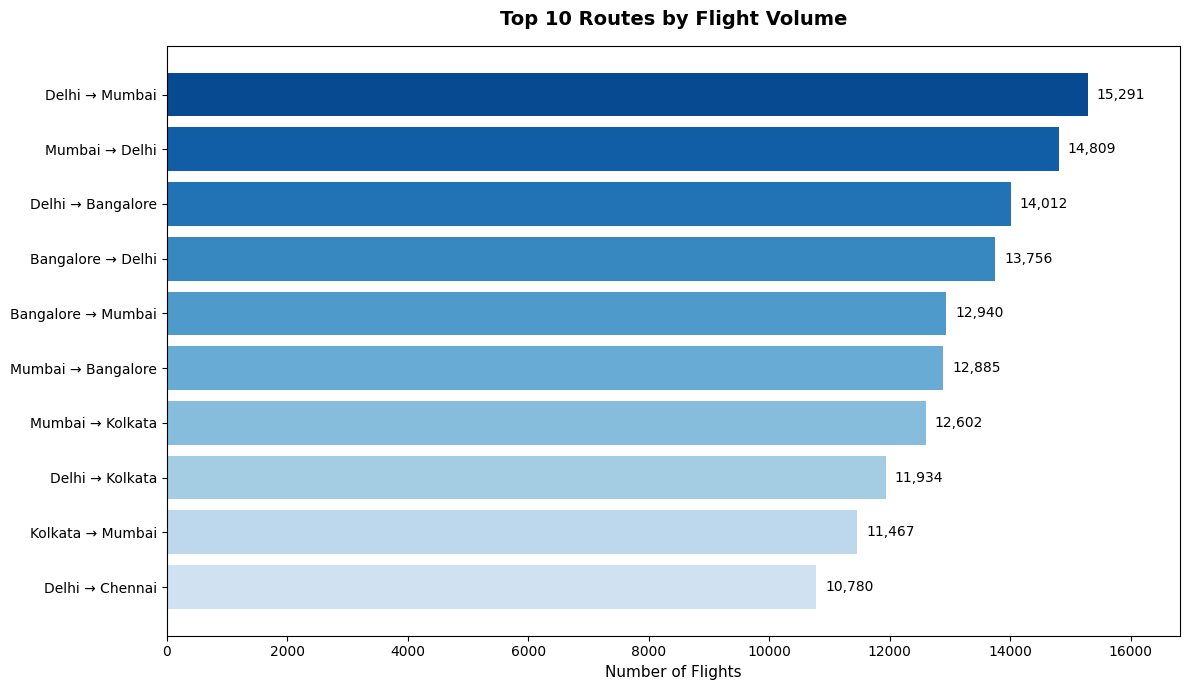

In [20]:
# 1. Data Preparation: Get top 10 routes by flight count
top_routes = df['route'].value_counts().head(10).sort_values(ascending=True)

# 2. Set up the figure
fig, ax = plt.subplots(figsize=(12, 7))

# Generate gradient blues color palette matching the chart
colors = plt.cm.Blues(np.linspace(0.2, 0.9, len(top_routes)))

# Horizontal bar chart
bars = ax.barh(top_routes.index, top_routes.values, color=colors)

# Title & Labels
ax.set_title(
    'Top 10 Routes by Flight Volume', fontsize=14, fontweight='bold', pad=15
)
ax.set_xlabel('Number of Flights', fontsize=11)

# Add exact value labels next to each bar
for bar in bars:
  width = bar.get_width()
  ax.text(
      width + 150,
      bar.get_y() + bar.get_height() / 2,
      f'{int(width):,}',
      va='center',
      ha='left',
      fontsize=10,
      color='black',
  )

# Set x-axis limit for visual padding
ax.set_xlim(0, max(top_routes.values) * 1.1)

# Layout adjustments
plt.tight_layout()
plt.show()